# 🌍 Landslide Detection Using Deep Learning

## 1. Project Overview

This project focuses on detecting landslide-affected regions from satellite imagery using deep learning and semantic segmentation.

A U-Net-based deep learning architecture is implemented using PyTorch to identify landslide regions at the pixel level. The model processes multi-spectral satellite images and generates binary segmentation masks to distinguish landslide-affected areas from non-landslide regions.

The project covers dataset exploration, preprocessing, model development, training, evaluation, and landslide prediction.

### Key Technologies
- **Python** – Programming language
- **PyTorch** – Deep learning framework
- **NumPy & Pandas** – Data processing
- **Matplotlib** – Data visualization
- **HDF5 (h5py)** – Dataset handling
- **Scikit-learn** – Dataset splitting

### Project Type
- **Domain:** Remote Sensing & Disaster Management
- **Task:** Binary Semantic Segmentation
- **Model:** U-Net
- **Input:** Multi-spectral satellite imagery
- **Output:** Pixel-wise landslide segmentation mask

In [1]:
import os
import random
import glob
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DATA_PATH = "/kaggle/input/datasets/satyearth/landslide/dataset"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("GPU Available:", torch.cuda.is_available())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Dataset Exists:", os.path.exists(DATA_PATH))

assert os.path.exists(DATA_PATH), "Dataset path not found!"

PyTorch: 2.11.0+cu130
NumPy: 2.1.3
GPU Available: True
Device: cuda
GPU: Tesla T4
Dataset Exists: True


## 2. Dataset Structure Exploration

Before preprocessing and model development, the dataset directory structure is examined to understand how the satellite images and their corresponding segmentation masks are organized.

This step helps verify the dataset organization and identify the files required for training and evaluation.

The directory structure is displayed recursively to inspect the available folders and subfolders.

In [2]:
for root, dirs, files in os.walk(DATA_PATH):
    level = root.replace(DATA_PATH, "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")

    if level >= 2:
        dirs[:] = []

dataset/
  test/
    img/
  train/
    img/
    mask/
  validation/
    img/


## 3. Dataset Loading and Initial Inspection

The dataset is organized into three main subsets:

- **Training Set:** Contains satellite images and their corresponding ground-truth segmentation masks.
- **Validation Set:** Contains unlabeled satellite images.
- **Test Set:** Contains satellite images reserved for prediction and inference.

The dataset files are stored in HDF5 (`.h5`) format.

In this step, the following checks are performed:

1. Load the file paths for training images, training masks, validation images, and test images.
2. Count the available files in each subset.
3. Verify that the required dataset files are present.
4. Inspect the shape and data type of a sample satellite image and its corresponding mask.

These checks help establish the dataset dimensions and confirm that the files can be accessed correctly.

In [3]:
train_images = sorted(glob.glob(f"{DATA_PATH}/train/img/*.h5"))
train_masks = sorted(glob.glob(f"{DATA_PATH}/train/mask/*.h5"))

val_images = sorted(glob.glob(f"{DATA_PATH}/validation/img/*.h5"))
test_images = sorted(glob.glob(f"{DATA_PATH}/test/img/*.h5"))

print("Train Images:", len(train_images))
print("Train Masks:", len(train_masks))
print("Unlabeled Validation Images:", len(val_images))
print("Test Images:", len(test_images))

assert len(train_images) > 0, "No training images found!"
assert len(train_masks) > 0, "No training masks found!"
assert len(val_images) > 0, "No validation images found!"
assert len(test_images) > 0, "No test images found!"

with h5py.File(train_images[0], "r") as f:
    print("\nImage Shape:", f["img"].shape)
    print("Image Dtype:", f["img"].dtype)

with h5py.File(train_masks[0], "r") as f:
    print("\nMask Shape:", f["mask"].shape)
    print("Mask Dtype:", f["mask"].dtype)

Train Images: 3799
Train Masks: 3799
Unlabeled Validation Images: 245
Test Images: 800

Image Shape: (128, 128, 14)
Image Dtype: float64

Mask Shape: (128, 128)
Mask Dtype: uint8


## 4. Image-Mask Pair Verification

For supervised semantic segmentation, every training satellite image must have its corresponding ground-truth segmentation mask.

In this step, unique identifiers are extracted from the image and mask filenames to establish the correct pairing.

The following validation checks are performed:

- Check for duplicate image identifiers.
- Check for duplicate mask identifiers.
- Verify that image and mask identifiers match exactly.
- Reorder the mask file paths to maintain the same order as the training images.

This ensures that each satellite image is associated with its correct segmentation mask, preventing incorrect label assignments during model training.

In [4]:
image_ids = [
    os.path.basename(p).replace("image_", "").replace(".h5", "")
    for p in train_images
]

mask_ids = [
    os.path.basename(p).replace("mask_", "").replace(".h5", "")
    for p in train_masks
]

assert len(image_ids) == len(set(image_ids)), "Duplicate image IDs!"
assert len(mask_ids) == len(set(mask_ids)), "Duplicate mask IDs!"
assert set(image_ids) == set(mask_ids), "Image-mask IDs mismatch!"

mask_path_by_id = {
    os.path.basename(p).replace("mask_", "").replace(".h5", ""): p
    for p in train_masks
}

train_masks = [
    mask_path_by_id[
        os.path.basename(p).replace("image_", "").replace(".h5", "")
    ]
    for p in train_images
]

print("Matching Image-Mask Pairs:", len(train_images))
print("Pairing Correct: True")

Matching Image-Mask Pairs: 3799
Pairing Correct: True


## 5. Visualizing Satellite Images and Ground-Truth Masks

Visual inspection is performed to understand the satellite imagery and its corresponding landslide segmentation masks.

A sample HDF5 image and its ground-truth mask are loaded for visualization.

### Visualization Components

1. **Satellite Image:** Displays the selected RGB composite using bands 4, 3, and 2.
2. **Ground-Truth Mask:** Displays the corresponding binary landslide segmentation mask.
3. **Overlay Visualization:** Combines the satellite image and segmentation mask to visually inspect the spatial alignment of landslide regions.

For better visualization, percentile-based contrast stretching is applied to the RGB channels.

The image and mask dimensions, along with the unique mask values, are also inspected to understand the input data and segmentation labels.

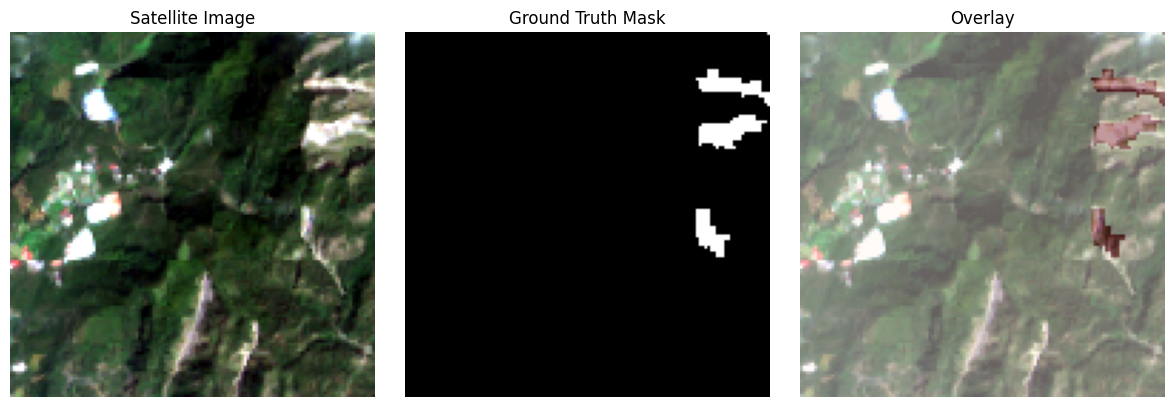

Image Shape: (128, 128, 14)
Mask Shape: (128, 128)
Mask Values: [0 1]


In [5]:
with h5py.File(train_images[0], "r") as f:
    image = f["img"][:].astype(np.float32)

with h5py.File(train_masks[0], "r") as f:
    mask = f["mask"][:]

rgb = image[:, :, [3, 2, 1]].copy()

for c in range(3):
    p2, p98 = np.percentile(rgb[:, :, c], [2, 98])
    rgb[:, :, c] = np.clip(
        (rgb[:, :, c] - p2) / (p98 - p2 + 1e-8), 0, 1
    )

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(rgb)
axes[0].set_title("Satellite Image")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground Truth Mask")

axes[2].imshow(rgb)
axes[2].imshow(mask, cmap="Reds", alpha=0.4, vmin=0, vmax=1)
axes[2].set_title("Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Image Shape:", image.shape)
print("Mask Shape:", mask.shape)
print("Mask Values:", np.unique(mask))

## 6. Dataset Class Distribution Analysis

Understanding the distribution of landslide and background pixels is important for evaluating class imbalance in semantic segmentation tasks.

In this step, all training masks are examined to calculate the distribution of landslide-affected and non-landslide regions.

### Analysis Performed

- **Positive Masks:** Number of masks containing at least one landslide pixel.
- **Empty Masks:** Number of masks containing only background pixels.
- **Landslide Pixels:** Total number of pixels representing landslide regions.
- **Background Pixels:** Total number of pixels representing non-landslide regions.
- **Landslide Pixel Percentage:** Proportion of landslide pixels relative to all pixels in the training masks.

This analysis helps identify the degree of class imbalance in the dataset and provides useful information for selecting an appropriate loss function during model training.

In [6]:
positive, empty = 0, 0
landslide_pixels, total_pixels = 0, 0

for path in train_masks:
    with h5py.File(path, "r") as f:
        mask = f["mask"][:]

    positive += int(mask.any())
    empty += int(not mask.any())

    landslide_pixels += np.count_nonzero(mask)
    total_pixels += mask.size

background_pixels = total_pixels - landslide_pixels

print("Total Masks:", len(train_masks))
print("Positive Masks:", positive)
print("Empty Masks:", empty)
print("Landslide Pixels:", landslide_pixels)
print("Background Pixels:", background_pixels)
print("Landslide Pixel Percentage:",
      round(100 * landslide_pixels / total_pixels, 4), "%")

Total Masks: 3799
Positive Masks: 2231
Empty Masks: 1568
Landslide Pixels: 1442790
Background Pixels: 60800026
Landslide Pixel Percentage: 2.318 %


## 7. Landslide Area Coverage Analysis

This section analyzes the percentage of landslide-affected pixels in each training mask.

For every mask, landslide coverage is calculated as the percentage of positive pixels relative to the total number of pixels.

The following statistical measures are calculated:

- **Minimum Coverage:** Lowest landslide coverage among the training masks.
- **Maximum Coverage:** Highest landslide coverage among the training masks.
- **Mean Coverage:** Average landslide coverage across all training masks.
- **Median Coverage:** Middle value of the landslide coverage distribution.

This analysis provides insight into the variation in landslide-affected areas across different satellite images and helps understand the spatial distribution of the target class.

In [7]:
areas = []

for path in train_masks:
    with h5py.File(path, "r") as f:
        mask = f["mask"][:]

    coverage = (np.count_nonzero(mask) / mask.size) * 100
    areas.append(coverage)

areas = np.array(areas, dtype=np.float32)

print("Minimum Coverage:", areas.min(), "%")
print("Maximum Coverage:", areas.max(), "%")
print("Mean Coverage:", areas.mean(), "%")
print("Median Coverage:", np.median(areas), "%")

Minimum Coverage: 0.0 %
Maximum Coverage: 47.53418 %
Mean Coverage: 2.3180025 %
Median Coverage: 0.3112793 %


## 8. Distribution of Landslide Coverage

A histogram is used to visualize the distribution of landslide coverage percentages across the training dataset.

The histogram groups training images into coverage intervals and displays the number of images falling within each interval.

This visualization helps identify:

- The frequency of images with different landslide coverage levels.
- Whether most images contain small or large landslide-affected regions.
- Variations in landslide coverage across the dataset.
- Potential imbalance in the distribution of landslide area sizes.

This analysis provides a visual understanding of the target segmentation distribution before model development.

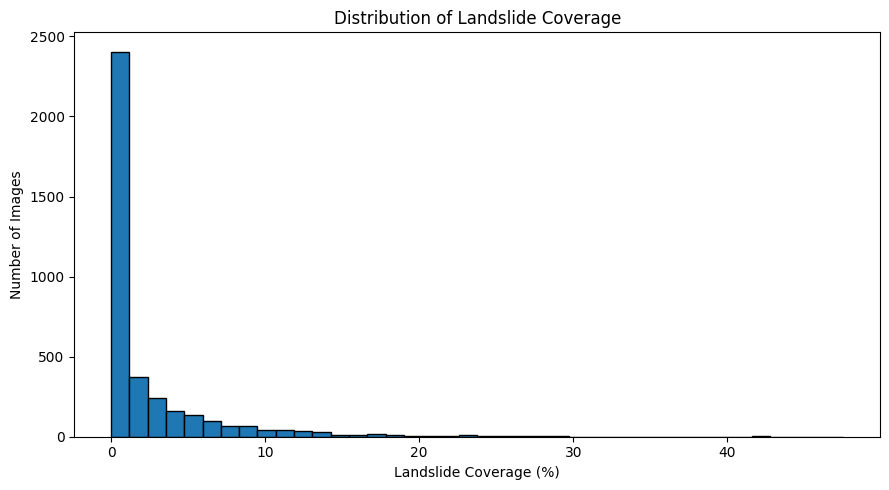

In [8]:
plt.figure(figsize=(9, 5))

plt.hist(areas, bins=40, edgecolor="black")

plt.xlabel("Landslide Coverage (%)")
plt.ylabel("Number of Images")
plt.title("Distribution of Landslide Coverage")

plt.tight_layout()
plt.show()

## 9. Training and Validation Data Split

The labeled training dataset is divided into separate training and validation subsets to support model development and performance evaluation.

An 80:20 split is applied:

- **80% Training Data:** Used to train the U-Net segmentation model.
- **20% Validation Data:** Used to evaluate model performance during training.

### Stratified Splitting

Stratified sampling is applied using mask-level labels:

- Positive samples contain at least one landslide pixel.
- Empty samples contain only background pixels.

The `train_test_split` function from Scikit-learn is used with a fixed random seed to ensure reproducibility.

This approach helps maintain a similar proportion of positive and empty masks in both subsets.

In [9]:
indices = np.arange(len(train_images))

labels = (areas > 0).astype(np.int64)

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=labels
)

train_image_paths = [train_images[i] for i in train_idx]
train_mask_paths = [train_masks[i] for i in train_idx]

val_image_paths = [train_images[i] for i in val_idx]
val_mask_paths = [train_masks[i] for i in val_idx]

print("Training Images:", len(train_image_paths))
print("Training Masks:", len(train_mask_paths))

print("Validation Images:", len(val_image_paths))
print("Validation Masks:", len(val_mask_paths))

print("\nTraining Positive Masks:", sum(labels[train_idx]))
print("Training Empty Masks:", len(train_idx) - sum(labels[train_idx]))

print("Validation Positive Masks:", sum(labels[val_idx]))
print("Validation Empty Masks:", len(val_idx) - sum(labels[val_idx]))

Training Images: 3039
Training Masks: 3039
Validation Images: 760
Validation Masks: 760

Training Positive Masks: 1785
Training Empty Masks: 1254
Validation Positive Masks: 446
Validation Empty Masks: 314


## 10. Computing Channel-Wise Mean and Standard Deviation

The satellite imagery contains 14 spectral channels. Since different spectral channels may have different numerical distributions, channel-wise normalization statistics are calculated before model training.

The mean and standard deviation are computed across all pixels in the training subset for each of the 14 channels.

### Statistical Calculations

- **Channel Mean:** Average pixel value calculated independently for each spectral channel.
- **Channel Standard Deviation:** Measures the variation of pixel values within each channel.

### Why This Step Is Important

Channel-wise statistics provide the necessary parameters for standardizing satellite imagery.

These statistics will be used during preprocessing to normalize the input images, helping maintain consistent input distributions and supporting stable model optimization.

**Note:** Only the training subset is used to calculate these statistics to prevent information leakage from the validation subset.

In [10]:
channel_sum = np.zeros(14, dtype=np.float64)
channel_sq_sum = np.zeros(14, dtype=np.float64)
total_pixels = 0

for path in train_image_paths:
    with h5py.File(path, "r") as f:
        image = f["img"][:].astype(np.float64)

    pixels = image.reshape(-1, 14)

    channel_sum += pixels.sum(axis=0)
    channel_sq_sum += (pixels ** 2).sum(axis=0)

    total_pixels += pixels.shape[0]

channel_mean = channel_sum / total_pixels

channel_var = channel_sq_sum / total_pixels - channel_mean ** 2
channel_std = np.sqrt(np.maximum(channel_var, 0))

channel_std = np.maximum(channel_std, 1e-6)

print("Channel Mean:", channel_mean)
print("\nChannel Std:", channel_std)

print("\nNumber of Channels:", len(channel_mean))

Channel Mean: [0.92695019 0.92395438 0.95445913 0.96145684 1.02217704 1.03861919
 1.03168838 1.04253889 1.16431983 1.16859808 1.04732963 1.03613432
 1.24693791 1.63729347]

Channel Std: [0.14202559 0.22197226 0.32012102 0.57738763 0.46414151 0.44816478
 0.46653768 0.49639742 0.51467428 0.68160944 0.53598093 0.66870871
 0.68281193 1.07593094]

Number of Channels: 14


## 11. Custom PyTorch Dataset Class

A custom PyTorch Dataset class is implemented to load and preprocess satellite images and their corresponding segmentation masks directly from HDF5 files.

The `LandslideDataset` class supports both labeled and unlabeled datasets.

### Image Preprocessing

1. Load satellite imagery from HDF5 files.
2. Convert image data into `float32`.
3. Apply channel-wise standardization using the previously calculated training statistics.
4. Convert images into PyTorch tensors.
5. Rearrange image dimensions from Height × Width × Channels (HWC) to Channels × Height × Width (CHW).

### Mask Processing

For labeled datasets:

1. Load the corresponding ground-truth mask.
2. Convert mask values into `float32`.
3. Add a channel dimension to match the segmentation output format.

### Dataset Modes

- **Labeled Mode:** Returns an image tensor and its corresponding mask tensor.
- **Unlabeled Mode:** Returns only the preprocessed image tensor.

This custom dataset class provides a consistent data-loading pipeline for training, validation, and prediction.

In [11]:
class LandslideDataset(Dataset):
    def __init__(self, image_paths, mask_paths=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]

        with h5py.File(image_path, "r") as f:
            image = f["img"][:].astype(np.float32)

        image = (image - channel_mean) / channel_std
        image = torch.from_numpy(image).permute(2, 0, 1).float()

        if self.mask_paths is None:
            return image

        mask_path = self.mask_paths[idx]

        with h5py.File(mask_path, "r") as f:
            mask = f["mask"][:].astype(np.float32)

        mask = torch.from_numpy(mask).unsqueeze(0).float()

        return image, mask


print("LandslideDataset class ready!")

LandslideDataset class ready!


## 12. Creating Training and Validation DataLoaders

The custom dataset instances are used to create PyTorch DataLoaders for efficient batch-wise data processing.

### DataLoader Configuration

- **Batch Size:** 16 samples per batch.
- **Number of Workers:** 2 subprocesses for data loading.
- **Training Shuffle:** Enabled to randomize the training sample order.
- **Validation Shuffle:** Disabled to maintain a consistent sample order.
- **Pinned Memory:** Enabled when a CUDA-compatible GPU is available to support efficient CPU-to-GPU data transfer.

### DataLoader Initialization

Two separate DataLoaders are created:

- **Training DataLoader:** Supplies satellite images and corresponding masks for model optimization.
- **Validation DataLoader:** Supplies labeled validation samples for evaluating model performance.

The number of samples and batches in each subset is also verified.

These DataLoaders establish the input pipeline for the U-Net training process.

In [12]:
BATCH_SIZE = 16
NUM_WORKERS = 2

train_ds = LandslideDataset(
    train_image_paths,
    train_mask_paths
)

val_ds = LandslideDataset(
    val_image_paths,
    val_mask_paths
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("Training Samples:", len(train_ds))
print("Validation Samples:", len(val_ds))
print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Batch Size:", BATCH_SIZE)

Training Samples: 3039
Validation Samples: 760
Training Batches: 190
Validation Batches: 48
Batch Size: 16


## 13. DataLoader Batch Verification

Before starting model development and training, a batch of samples is retrieved from the training DataLoader to verify the correctness of the data pipeline.

### Verification Checks

- **Image Batch Shape:** Confirms that input images contain 14 spectral channels.
- **Mask Batch Shape:** Confirms that segmentation masks contain a single channel.
- **Data Types:** Verifies that images and masks are represented as `float32` tensors.
- **Image Value Range:** Inspects the minimum and maximum normalized pixel values.
- **Mask Values:** Checks the unique values present in the segmentation masks.
- **Batch Consistency:** Ensures that images and masks contain the same number of samples.

Assertions are used to verify the expected tensor dimensions and batch consistency.

Successful execution confirms that the DataLoader provides correctly structured batches for the segmentation model.

In [13]:
images, masks = next(iter(train_loader))

print("Image Batch Shape:", images.shape)
print("Mask Batch Shape:", masks.shape)

print("Image Dtype:", images.dtype)
print("Mask Dtype:", masks.dtype)

print("Image Min:", images.min().item())
print("Image Max:", images.max().item())

print("Mask Unique Values:", torch.unique(masks))

assert images.shape[1] == 14
assert masks.shape[1] == 1
assert images.shape[0] == masks.shape[0]

print("\nBatch Sanity Check Passed!")

Image Batch Shape: torch.Size([16, 14, 128, 128])
Mask Batch Shape: torch.Size([16, 1, 128, 128])
Image Dtype: torch.float32
Mask Dtype: torch.float32
Image Min: -6.526641845703125
Image Max: 18.203563690185547
Mask Unique Values: tensor([0., 1.])

Batch Sanity Check Passed!


## 14. U-Net Architecture

U-Net is a convolutional neural network architecture widely used for biomedical image segmentation and other pixel-level image analysis tasks.

In this project, a custom U-Net architecture is implemented using PyTorch to perform binary semantic segmentation of landslide-affected regions from multi-spectral satellite imagery.

### Architecture Overview

The network consists of two main components:

**1. Encoder (Contracting Path)**

The encoder progressively extracts spatial and contextual features from the input satellite imagery using convolutional blocks and max-pooling operations.

It contains four encoder stages with 64, 128, 256, and 512 feature channels, respectively.

**2. Bottleneck**

The bottleneck forms the deepest part of the network and processes high-level feature representations using 1024 channels.

**3. Decoder (Expanding Path)**

The decoder progressively reconstructs spatial resolution using transposed convolution layers and concatenates encoder features through skip connections.

These skip connections help preserve spatial information and improve the localization of landslide boundaries.

### Double Convolution Block

Each convolutional block consists of:

- Two 3 × 3 convolutional layers.
- Batch Normalization after each convolution.
- ReLU activation functions.

### Model Configuration

| Parameter | Configuration |
|---|---|
| Architecture | U-Net |
| Input Channels | 14 |
| Output Channels | 1 |
| Encoder Channels | 64, 128, 256, 512 |
| Bottleneck Channels | 1024 |
| Convolution Kernel | 3 × 3 |
| Upsampling | Transposed Convolution |
| Skip Connections | Enabled |
| Output | Binary Segmentation Logits |

The final 1 × 1 convolution produces a single-channel segmentation map containing raw logits for each pixel.

This architecture enables the model to learn both high-level spectral features and fine-grained spatial information for landslide detection.

In [14]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=14, out_channels=1):
        super().__init__()

        self.enc1 = DoubleConv(in_channels, 64)
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = DoubleConv(64, 128)
        self.pool2 = nn.MaxPool2d(2)

        self.enc3 = DoubleConv(128, 256)
        self.pool3 = nn.MaxPool2d(2)

        self.enc4 = DoubleConv(256, 512)
        self.pool4 = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(512, 1024)

        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        self.final = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))

        b = self.bottleneck(self.pool4(e4))

        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final(d1)


model = UNet().to(device)

total_params = sum(p.numel() for p in model.parameters())

print("Model: U-Net")
print("Input Channels: 14")
print("Output Channels: 1")
print("Total Parameters:", f"{total_params:,}")
print("Device:", device)

Model: U-Net
Input Channels: 14
Output Channels: 1
Total Parameters: 31,049,857
Device: cuda


## 15. Loss Function and Optimizer

To train the U-Net model effectively, a combined Binary Cross-Entropy (BCE) and Dice Loss function is implemented.

### 1. Binary Cross-Entropy Loss (BCE)

BCE measures the difference between the predicted pixel probabilities and the ground-truth segmentation masks.

The `binary_cross_entropy_with_logits` function is used to calculate BCE directly from raw model logits, providing numerically stable loss computation.

### 2. Dice Loss

Dice Loss measures the overlap between predicted landslide regions and ground-truth masks.

It is calculated using the Dice coefficient:

\[
Dice = \frac{2|P \cap G| + \epsilon}{|P| + |G| + \epsilon}
\]

Where:

- \(P\) represents predicted probabilities.
- \(G\) represents ground-truth masks.
- \(\epsilon\) is a smoothing constant.

Dice Loss is defined as:

\[
DiceLoss = 1 - Dice
\]

### 3. Combined Loss Function

The final training objective combines both loss functions:

\[
TotalLoss = BCELoss + DiceLoss
\]

BCE encourages accurate pixel-wise classification, while Dice Loss focuses on the overlap between predicted and actual landslide regions.

### 4. Optimizer

The Adam optimizer is selected to update the model parameters during training.

| Parameter | Configuration |
|---|---|
| Loss Function | BCE + Dice Loss |
| Optimizer | Adam |
| Learning Rate | 0.0001 |
| Smoothing Factor | 1.0 |

The combination of BCE and Dice Loss provides a balanced training objective for binary landslide segmentation.

In [15]:
class BCEDiceLoss(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets)

        probs = torch.sigmoid(logits)

        smooth = 1.0

        intersection = (probs * targets).sum()
        dice = (
            2.0 * intersection + smooth
        ) / (
            probs.sum() + targets.sum() + smooth
        )

        dice_loss = 1.0 - dice

        return bce + dice_loss


criterion = BCEDiceLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

print("Loss Function: BCE + Dice Loss")
print("Optimizer: Adam")
print("Learning Rate:", 1e-4)

Loss Function: BCE + Dice Loss
Optimizer: Adam
Learning Rate: 0.0001


## 16. Training and Validation Pipeline

A reusable training and evaluation function named `run_epoch()` is implemented to manage the model training and validation process.

The function supports two execution modes:

### 1. Training Mode

When training is enabled:

- The model is switched to training mode using `model.train()`.
- Satellite images and their corresponding masks are transferred to the selected computation device.
- Model predictions are generated through forward propagation.
- The combined BCE + Dice Loss is calculated.
- Gradients are computed through backpropagation.
- Model parameters are updated using the Adam optimizer.

### 2. Validation Mode

When training is disabled:

- The model is switched to evaluation mode using `model.eval()`.
- Gradient computation is disabled.
- Predictions and loss are calculated without updating model parameters.

### Evaluation Metrics

The function calculates three important metrics:

**Average Loss:** Measures the overall prediction error across the processed samples.

**Dice Coefficient:** Measures the overlap between predicted landslide regions and ground-truth masks.

\[
Dice = \frac{2TP}{2TP + FP + FN}
\]

**Intersection over Union (IoU):** Measures the ratio of intersection to union between predicted and actual landslide regions.

\[
IoU = \frac{TP}{TP + FP + FN}
\]

Where:

- **TP:** True Positive pixels.
- **FP:** False Positive pixels.
- **FN:** False Negative pixels.

Predictions are converted into binary masks using a probability threshold of 0.5.

The function returns average loss, Dice coefficient, and IoU for each epoch.

In [16]:
def run_epoch(loader, training=True):

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_samples = 0

    total_tp = 0
    total_fp = 0
    total_fn = 0

    for images, masks in loader:

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            logits = model(images)
            loss = criterion(logits, masks)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = images.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        predictions = torch.sigmoid(logits) >= 0.5
        targets = masks >= 0.5

        total_tp += (predictions & targets).sum().item()
        total_fp += (predictions & ~targets).sum().item()
        total_fn += (~predictions & targets).sum().item()

    avg_loss = total_loss / total_samples

    dice = (
        2 * total_tp
    ) / (
        2 * total_tp + total_fp + total_fn + 1e-7
    )

    iou = (
        total_tp
    ) / (
        total_tp + total_fp + total_fn + 1e-7
    )

    return avg_loss, dice, iou


print("run_epoch() function ready!")

run_epoch() function ready!


## 17. Model Training Configuration

Before starting the training process, the required training parameters and experiment-tracking variables are initialized.

### Training Configuration

| Parameter | Value |
|---|---|
| Total Epochs | 30 |
| Best Dice Initialization | -1.0 |
| Model Selection Metric | Validation Dice |
| Checkpoint Format | PyTorch `.pth` |
| Checkpoint Location | `/kaggle/working/best_unet.pth` |

### Training History

A history dictionary is created to record the following metrics after each epoch:

- Training Loss
- Validation Loss
- Training Dice Score
- Validation Dice Score
- Training IoU
- Validation IoU

### Best Model Tracking

The best-performing model is selected based on its validation Dice score.

The `best_dice` and `best_epoch` variables track the highest validation Dice score and its corresponding epoch.

The checkpoint path specifies where the best model will be saved during training.

This configuration enables systematic experiment tracking and model selection throughout the training process.

In [17]:
EPOCHS = 30

best_dice = -1.0
best_epoch = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_dice": [],
    "val_dice": [],
    "train_iou": [],
    "val_iou": []
}

CHECKPOINT_PATH = "/kaggle/working/best_unet.pth"

print("Epochs:", EPOCHS)
print("Checkpoint:", CHECKPOINT_PATH)
print("Training configuration ready!")

Epochs: 30
Checkpoint: /kaggle/working/best_unet.pth
Training configuration ready!


## 18. Model Training

The U-Net model is trained using the prepared training DataLoader and evaluated using the labeled validation DataLoader.

The training process runs for a maximum of 30 epochs.

### Training Workflow

For each epoch, the following operations are performed:

1. **Training Phase:** The model learns from satellite images and their corresponding ground-truth masks.
2. **Validation Phase:** The model is evaluated on the held-out validation subset without updating its parameters.
3. **Metric Recording:** Training and validation loss, Dice score, and IoU are stored in the history dictionary.
4. **Progress Monitoring:** Epoch-wise training and validation metrics are displayed.
5. **Best Model Selection:** The model checkpoint is saved whenever the validation Dice score improves.

### Model Checkpointing

The model parameters are saved to:

`/kaggle/working/best_unet.pth`

Only the model state dictionary is stored, keeping the checkpoint focused on the learned parameters.

### Training Completion

After all epochs are completed, the following information is reported:

- Best-performing epoch.
- Highest validation Dice score.
- Training completion status.

The checkpoint with the highest validation Dice score is retained for subsequent evaluation and prediction.

In [18]:
for epoch in range(EPOCHS):

    train_loss, train_dice, train_iou = run_epoch(
        train_loader,
        training=True
    )

    val_loss, val_dice, val_iou = run_epoch(
        val_loader,
        training=False
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    history["train_iou"].append(train_iou)
    history["val_iou"].append(val_iou)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Dice: {train_dice:.4f} | "
        f"Val Dice: {val_dice:.4f} | "
        f"Val IoU: {val_iou:.4f}"
    )

    if val_dice > best_dice:

        best_dice = val_dice
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            CHECKPOINT_PATH
        )

        print("Best model saved!")

print("\nTraining Completed!")
print("Best Epoch:", best_epoch)
print("Best Validation Dice:", round(best_dice, 4))

Epoch [1/30] Train Loss: 1.2502 | Val Loss: 1.1476 | Train Dice: 0.4558 | Val Dice: 0.5322 | Val IoU: 0.3626
Best model saved!
Epoch [2/30] Train Loss: 1.0682 | Val Loss: 1.0146 | Train Dice: 0.6180 | Val Dice: 0.6638 | Val IoU: 0.4968
Best model saved!
Epoch [3/30] Train Loss: 0.9548 | Val Loss: 0.9196 | Train Dice: 0.6550 | Val Dice: 0.6250 | Val IoU: 0.4546
Epoch [4/30] Train Loss: 0.8497 | Val Loss: 0.9991 | Train Dice: 0.6707 | Val Dice: 0.5967 | Val IoU: 0.4252
Epoch [5/30] Train Loss: 0.7497 | Val Loss: 0.7038 | Train Dice: 0.6866 | Val Dice: 0.7055 | Val IoU: 0.5450
Best model saved!
Epoch [6/30] Train Loss: 0.6605 | Val Loss: 0.6277 | Train Dice: 0.6983 | Val Dice: 0.7268 | Val IoU: 0.5708
Best model saved!
Epoch [7/30] Train Loss: 0.5773 | Val Loss: 0.5454 | Train Dice: 0.7119 | Val Dice: 0.7330 | Val IoU: 0.5785
Best model saved!
Epoch [8/30] Train Loss: 0.5150 | Val Loss: 0.4924 | Train Dice: 0.7148 | Val Dice: 0.7450 | Val IoU: 0.5936
Best model saved!
Epoch [9/30] Train L

## 19. Training Performance Visualization

The training history is visualized using Matplotlib to analyze the model's learning behavior across all completed epochs.

Two plots are generated to monitor model performance.

### 1. Training and Validation Loss

The first plot compares training loss and validation loss across epochs.

This visualization helps evaluate:

- Reduction in training error over time.
- Validation performance during model training.
- Differences between training and validation loss.
- Potential signs of overfitting or underfitting.

### 2. Segmentation Performance Metrics

The second plot displays:

- Training Dice Score.
- Validation Dice Score.
- Validation IoU Score.

These metrics help assess the model's ability to identify landslide regions and measure the overlap between predicted and ground-truth segmentation masks.

The visualized training history provides an overview of model convergence and generalization performance.

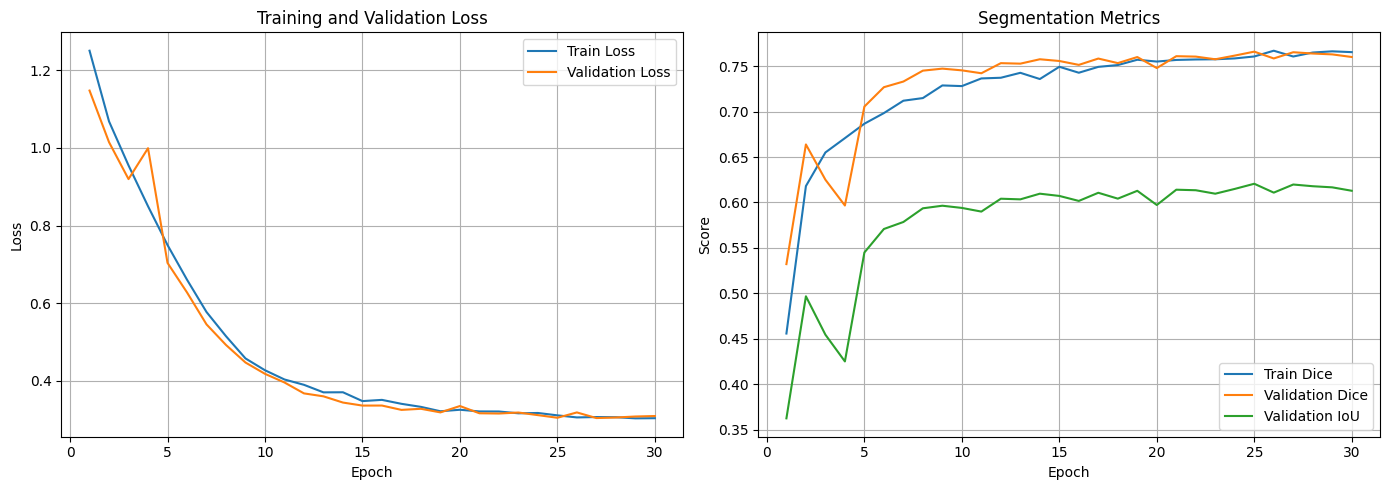

In [19]:
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history["train_loss"], label="Train Loss")
axes[0].plot(epochs_range, history["val_loss"], label="Validation Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs_range, history["train_dice"], label="Train Dice")
axes[1].plot(epochs_range, history["val_dice"], label="Validation Dice")
axes[1].plot(epochs_range, history["val_iou"], label="Validation IoU")
axes[1].set_title("Segmentation Metrics")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 20. Best Model Loading and Validation

After training is completed, the best-performing U-Net checkpoint is loaded using its saved model state dictionary.

The model is switched to evaluation mode to ensure that validation is performed without updating model parameters.

### Evaluation Procedure

1. Load the saved best model checkpoint.
2. Restore the learned model parameters.
3. Move the model to the selected computation device.
4. Set the model to evaluation mode.
5. Evaluate the model using the labeled validation DataLoader.

### Evaluation Metrics

The following metrics are calculated:

- **Validation Loss:** Measures prediction error on the validation dataset.
- **Validation Dice Score:** Measures the overlap between predicted and ground-truth landslide regions.
- **Validation IoU:** Measures the intersection over union of predicted and actual segmentation regions.

The best epoch and corresponding validation performance are also reported.

This step verifies the performance of the saved best model rather than relying only on the final training epoch.

In [20]:
model.load_state_dict(
    torch.load(CHECKPOINT_PATH, map_location=device)
)

model.to(device)
model.eval()

val_loss, val_dice, val_iou = run_epoch(
    val_loader,
    training=False
)

print("Best Epoch:", best_epoch)
print("Validation Loss:", round(val_loss, 4))
print("Validation Dice:", round(val_dice, 4))
print("Validation IoU:", round(val_iou, 4))

Best Epoch: 25
Validation Loss: 0.3049
Validation Dice: 0.7659
Validation IoU: 0.6206


## 21. Comprehensive Model Evaluation

The best-performing U-Net model is evaluated on the labeled validation dataset using pixel-level classification metrics.

A confusion matrix is constructed by accumulating the predicted and actual pixel classifications across all validation batches.

### Confusion Matrix Components

- **True Positive (TP):** Landslide pixels correctly identified as landslide.
- **False Positive (FP):** Background pixels incorrectly classified as landslide.
- **False Negative (FN):** Actual landslide pixels incorrectly classified as background.
- **True Negative (TN):** Background pixels correctly identified as background.

### Evaluation Metrics

**1. Precision**

Measures how many predicted landslide pixels are actually landslide pixels.

\[
Precision = \frac{TP}{TP+FP}
\]

**2. Recall**

Measures how many actual landslide pixels are successfully detected.

\[
Recall = \frac{TP}{TP+FN}
\]

**3. Dice Score**

Measures the overlap between predicted and ground-truth landslide regions.

\[
Dice = \frac{2TP}{2TP+FP+FN}
\]

**4. Intersection over Union (IoU)**

Measures the intersection relative to the union of predicted and actual landslide regions.

\[
IoU = \frac{TP}{TP+FP+FN}
\]

All metrics are calculated globally across the validation pixels using a probability threshold of 0.5.

These evaluation metrics provide a comprehensive assessment of the model's ability to identify landslide regions while accounting for both false detections and missed landslide pixels.

In [21]:
total_tp = 0
total_fp = 0
total_fn = 0
total_tn = 0

model.eval()

with torch.inference_mode():
    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        predictions = torch.sigmoid(logits) >= 0.5
        targets = masks >= 0.5

        total_tp += (predictions & targets).sum().item()
        total_fp += (predictions & ~targets).sum().item()
        total_fn += (~predictions & targets).sum().item()
        total_tn += (~predictions & ~targets).sum().item()

precision = total_tp / (total_tp + total_fp + 1e-7)
recall = total_tp / (total_tp + total_fn + 1e-7)

dice_score = (
    2 * total_tp
) / (
    2 * total_tp + total_fp + total_fn + 1e-7
)

iou_score = (
    total_tp
) / (
    total_tp + total_fp + total_fn + 1e-7
)

print("FINAL VALIDATION RESULTS")
print("-" * 35)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("Dice Score:", round(dice_score, 4))
print("IoU Score:", round(iou_score, 4))
print("True Positives:", total_tp)
print("False Positives:", total_fp)
print("False Negatives:", total_fn)
print("True Negatives:", total_tn)

FINAL VALIDATION RESULTS
-----------------------------------
Precision: 0.7512
Recall: 0.7811
Dice Score: 0.7659
IoU Score: 0.6206
True Positives: 215608
False Positives: 71407
False Negatives: 60413
True Negatives: 12104412


## 22. Visualizing Model Predictions on Validation Data

The trained U-Net model is used to generate a landslide segmentation prediction for a sample from the labeled validation dataset.

This visualization provides a qualitative assessment of the model's ability to identify landslide-affected regions.

### Visualization Components

1. **Satellite Image:** Displays the original multi-spectral satellite image as an RGB composite using bands 4, 3, and 2.
2. **Ground-Truth Mask:** Shows the actual landslide regions provided by the dataset.
3. **Predicted Mask:** Displays the binary segmentation mask generated by the trained U-Net model.
4. **Prediction Overlay:** Overlays the predicted landslide regions on the original satellite image for spatial interpretation.

### Prediction Process

- Load a validation image.
- Pass the preprocessed image through the trained model.
- Apply the sigmoid activation function to convert logits into probabilities.
- Apply a threshold of 0.5 to generate a binary segmentation mask.
- Calculate the predicted landslide coverage percentage.

The generated visualization is also saved as a PNG file for future reference.

This comparison helps identify correctly detected landslide regions, missed regions, and false positive predictions.

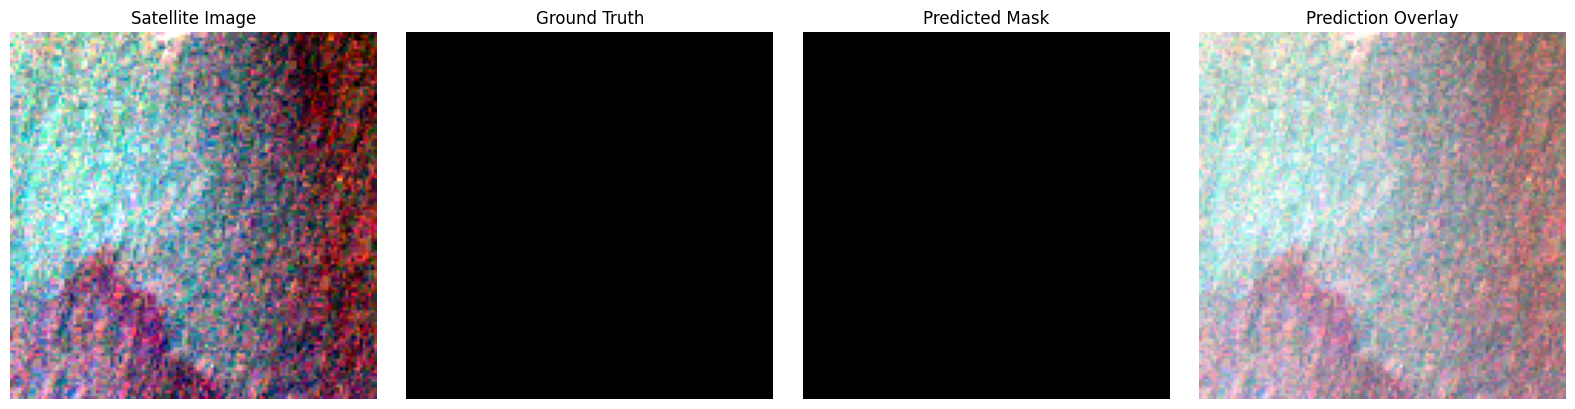

Predicted Landslide Coverage: 0.0 %


In [22]:
sample_idx = 0

image_tensor, true_mask = val_ds[sample_idx]

with torch.inference_mode():
    input_tensor = image_tensor.unsqueeze(0).to(device)
    logits = model(input_tensor)

    probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

predicted_mask = (probability >= 0.5).astype(np.uint8)
true_mask = true_mask.squeeze(0).numpy()

with h5py.File(val_image_paths[sample_idx], "r") as f:
    original_image = f["img"][:].astype(np.float32)

rgb = original_image[:, :, [3, 2, 1]].copy()

for c in range(3):
    p2, p98 = np.percentile(rgb[:, :, c], [2, 98])
    rgb[:, :, c] = np.clip(
        (rgb[:, :, c] - p2) / (p98 - p2 + 1e-8), 0, 1
    )

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(rgb)
axes[0].set_title("Satellite Image")

axes[1].imshow(true_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground Truth")

axes[2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Predicted Mask")

axes[3].imshow(rgb)
axes[3].imshow(predicted_mask, cmap="Reds", alpha=0.4)
axes[3].set_title("Prediction Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    "/kaggle/working/validation_prediction.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Predicted Landslide Coverage:",
      round(predicted_mask.mean() * 100, 2), "%")

## 23. Generating Predictions on the Test Dataset

This section performs inference on the unlabeled test dataset using the trained U-Net model.

The workflow includes:

- Loading each test image from its HDF5 file.
- Normalizing the 14-channel image using the training dataset's channel-wise mean and standard deviation.
- Passing the image through the trained model in evaluation mode.
- Applying the sigmoid activation to convert model logits into probability maps.
- Applying a threshold of 0.5 to generate binary segmentation masks.
- Classifying each image as **Landslide** or **No Landslide** based on its predicted mask.
- Calculating the number of predicted landslide pixels and their percentage of total image area.
- Collecting predictions and saving the results to a CSV file.

The generated CSV file, `landslide_test_predictions.csv`, contains the prediction summary for every test image.

**Note:** The test dataset is unlabeled, so ground-truth-based evaluation metrics such as Dice, IoU, precision, and recall cannot be calculated for this dataset. These predictions represent the model's inference results.

In [23]:
test_results = []

model.eval()

for idx, image_path in enumerate(test_images):

    with h5py.File(image_path, "r") as f:
        image = f["img"][:].astype(np.float32)

    normalized_image = (image - channel_mean) / channel_std

    input_tensor = torch.from_numpy(
        normalized_image
    ).permute(2, 0, 1).unsqueeze(0).float().to(device)

    with torch.inference_mode():
        logits = model(input_tensor)
        probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

    predicted_mask = (probability >= 0.5).astype(np.uint8)

    coverage = float(predicted_mask.mean() * 100)

    image_name = os.path.basename(image_path)

    test_results.append({
        "image_name": image_name,
        "prediction": "Landslide" if predicted_mask.any() else "No Landslide",
        "landslide_pixels": int(predicted_mask.sum()),
        "landslide_coverage_percent": coverage
    })

    if (idx + 1) % 100 == 0:
        print(f"Processed {idx + 1}/{len(test_images)} images")

test_df = pd.DataFrame(test_results)

CSV_PATH = "/kaggle/working/landslide_test_predictions.csv"
test_df.to_csv(CSV_PATH, index=False)

print("\nTest Prediction Summary")
print(test_df["prediction"].value_counts())

print("\nAverage Predicted Coverage:",
      round(test_df["landslide_coverage_percent"].mean(), 4), "%")

print("\nCSV Saved:", CSV_PATH)
display(test_df.head(10))

Processed 100/800 images
Processed 200/800 images
Processed 300/800 images
Processed 400/800 images
Processed 500/800 images
Processed 600/800 images
Processed 700/800 images
Processed 800/800 images

Test Prediction Summary
prediction
Landslide       661
No Landslide    139
Name: count, dtype: int64

Average Predicted Coverage: 2.9525 %

CSV Saved: /kaggle/working/landslide_test_predictions.csv


,image_name,prediction,landslide_pixels,landslide_coverage_percent
0,image_1.h5,Landslide,9,0.054932
1,image_10.h5,Landslide,1,0.006104
2,image_100.h5,Landslide,60,0.366211
3,image_101.h5,No Landslide,0,0.000000
4,image_102.h5,Landslide,131,0.799561
5,image_103.h5,Landslide,104,0.634766
6,image_104.h5,Landslide,14,0.085449
7,image_105.h5,Landslide,879,5.364990
8,image_106.h5,Landslide,13,0.079346
9,image_107.h5,Landslide,58,0.354004


## 24. Saving the Final Model and Verifying Project Artifacts

This section saves the final trained U-Net model checkpoint and verifies that all important project output files are available.

The final checkpoint includes:

- **Model weights:** The trained U-Net model's state dictionary.
- **Normalization parameters:** Training dataset channel-wise mean and standard deviation.
- **Input configuration:** The expected 14 input channels.
- **Prediction threshold:** A threshold of 0.5 for binary segmentation.
- **Best training epoch:** The epoch that achieved the highest validation Dice score.
- **Validation metrics:** Loss, precision, recall, Dice coefficient, and IoU.

The section also checks the existence and file sizes of the following project artifacts:

- Best model checkpoint.
- Final model checkpoint.
- Test dataset prediction CSV.
- Validation prediction visualization.

Finally, it prints the total number of test predictions, the best training epoch, and the best validation Dice score to provide a summary of the completed project pipeline.

The final checkpoint can be used later to restore the model and its associated preprocessing configuration for inference.

In [24]:
FINAL_CHECKPOINT = "/kaggle/working/final_unet_checkpoint.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "channel_mean": channel_mean,
    "channel_std": channel_std,
    "input_channels": 14,
    "threshold": 0.5,
    "best_epoch": best_epoch,
    "validation_metrics": {
        "loss": val_loss,
        "precision": precision,
        "recall": recall,
        "dice": dice_score,
        "iou": iou_score
    }
}, FINAL_CHECKPOINT)

print("FINAL PROJECT FILES")
print("-" * 40)

output_files = [
    CHECKPOINT_PATH,
    FINAL_CHECKPOINT,
    CSV_PATH,
    "/kaggle/working/validation_prediction.png"
]

for path in output_files:
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"FOUND: {os.path.basename(path)} ({size_mb:.2f} MB)")
    else:
        print(f"MISSING: {os.path.basename(path)}")

print("\nTotal Test Predictions:", len(test_df))
print("Best Epoch:", best_epoch)
print("Best Validation Dice:", round(best_dice, 4))
print("\nPROJECT PIPELINE COMPLETED!")

FINAL PROJECT FILES
----------------------------------------
FOUND: best_unet.pth (118.53 MB)
FOUND: final_unet_checkpoint.pth (118.54 MB)
FOUND: landslide_test_predictions.csv (0.03 MB)
FOUND: validation_prediction.png (0.15 MB)

Total Test Predictions: 800
Best Epoch: 25
Best Validation Dice: 0.7659

PROJECT PIPELINE COMPLETED!


## 25. Final Model Performance Summary

This section summarizes the performance of the trained U-Net model using the internal labeled validation dataset.

The model is evaluated using the following metrics:

- **Validation Loss:** Measures the difference between predicted segmentation outputs and ground-truth masks.
- **Precision:** Measures how many predicted landslide pixels are actually landslide pixels.
- **Recall:** Measures how many actual landslide pixels are correctly identified.
- **Dice Coefficient:** Measures the overlap between predicted segmentation masks and ground-truth masks.
- **Intersection over Union (IoU):** Measures the ratio of the intersection to the union of predicted and ground-truth landslide regions.

### Training Summary

The best model checkpoint is selected based on the highest validation Dice score during training.

The notebook also reports:

- Best training epoch.
- Best validation Dice score.
- Final validation metrics.
- Total number of test images processed.
- Number of images classified as Landslide and No Landslide.

### Important Evaluation Note

Validation metrics are calculated using labeled data from the internal validation split.

The test dataset is unlabeled. Therefore, its predictions are used for inference and result generation, not for calculating ground-truth-based performance metrics.

The reported validation performance should be considered the primary quantitative evaluation of this model. Test predictions should be interpreted as model-generated outputs rather than confirmed landslide detections.

In [25]:
print("=" * 50)
print("FINAL MODEL PERFORMANCE SUMMARY")
print("=" * 50)

print(f"Best Epoch       : {best_epoch}")
print(f"Best Val Dice    : {best_dice:.4f}")

print("\nValidation Metrics")
print("-" * 30)
print(f"Loss      : {val_loss:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"Dice      : {dice_score:.4f}")
print(f"IoU       : {iou_score:.4f}")

print("\nTest Dataset Summary")
print("-" * 30)
print(f"Total Images : {len(test_df)}")

print(test_df["prediction"].value_counts())

print(
    f"\nAverage Predicted Coverage: "
    f"{test_df['landslide_coverage_percent'].mean():.4f}%"
)

print("\n" + "=" * 50)
print("SUMMARY COMPLETED")
print("=" * 50)

FINAL MODEL PERFORMANCE SUMMARY
Best Epoch       : 25
Best Val Dice    : 0.7659

Validation Metrics
------------------------------
Loss      : 0.3049
Precision : 0.7512
Recall    : 0.7811
Dice      : 0.7659
IoU       : 0.6206

Test Dataset Summary
------------------------------
Total Images : 800
prediction
Landslide       661
No Landslide    139
Name: count, dtype: int64

Average Predicted Coverage: 2.9525%

SUMMARY COMPLETED


## 26. Understanding the Test Prediction CSV

The model generates a CSV file named `landslide_test_predictions.csv` containing prediction results for all test images.

This file provides a summarized view of the model's predictions without requiring users to open individual segmentation masks.

### CSV Columns Explained

| Column | Description |
|---|---|
| `image_name` | Name of the original test image. |
| `prediction` | Predicted image-level class: Landslide or No Landslide. |
| `landslide_pixels` | Total number of pixels predicted as landslide. |
| `landslide_coverage_percent` | Percentage of the image classified as landslide. |

### Understanding the Predictions

- **Landslide:** At least one pixel is classified as landslide.
- **No Landslide:** No pixels are classified as landslide.
- **Landslide Coverage:** Represents the proportion of the image predicted as landslide.

### Output File Location

The CSV file is saved at:

`/kaggle/working/landslide_test_predictions.csv`

Users can download this file from the Kaggle notebook's Output section.

### Important Note

The CSV contains model-generated predictions, not verified ground-truth labels. A prediction of Landslide does not necessarily confirm an actual landslide event.

## 27. Understanding Saved Model Checkpoints

The project saves two model checkpoint files in the Kaggle working directory.

### 1. Best Model Checkpoint – `best_unet.pth`

This file contains the model weights from the training epoch that achieved the highest validation Dice score.

**Purpose:**
- Stores the best-performing model weights.
- Can be used to restore the trained U-Net architecture.
- Useful for model evaluation and inference.

### 2. Final Model Checkpoint – `final_unet_checkpoint.pth`

This file contains the model weights along with additional information required for inference.

It includes:

- `model_state_dict`: Trained U-Net model parameters.
- `channel_mean`: Channel-wise normalization means.
- `channel_std`: Channel-wise normalization standard deviations.
- `input_channels`: Expected number of input channels (14).
- `threshold`: Binary prediction threshold (0.5).
- `best_epoch`: Best-performing training epoch.
- `validation_metrics`: Saved validation loss, precision, recall, Dice, and IoU.

### Which Checkpoint Should Be Used?

For convenient model reuse and inference, `final_unet_checkpoint.pth` is recommended because it stores both model weights and preprocessing configuration.

The `best_unet.pth` file is useful when only the trained model parameters are required.

### File Location

Both checkpoint files are saved in:

`/kaggle/working/`

**Important:** The U-Net architecture definition must be available when loading either checkpoint. The final checkpoint stores model parameters and configuration, not the complete Python model architecture.

## 28. Loading the Trained Model for Inference

A trained model can be restored from the saved checkpoint without training the network again.

The final checkpoint contains the trained model parameters and the preprocessing configuration required for inference.

### Loading Workflow

1. Define the same U-Net architecture used during training.
2. Instantiate the model with 14 input channels and 1 output channel.
3. Load the saved checkpoint.
4. Restore the model weights.
5. Retrieve the channel-wise normalization parameters and prediction threshold.
6. Set the model to evaluation mode.

The restored model can then be used to generate predictions on new satellite images.

**Note:** The U-Net architecture definition must be executed before loading the checkpoint. The checkpoint does not contain the architecture's Python class definition.

In [26]:
# Load the final trained checkpoint

FINAL_CHECKPOINT = "/kaggle/working/final_unet_checkpoint.pth"

checkpoint = torch.load(
    FINAL_CHECKPOINT,
    map_location=device,
    weights_only=False
)

# Initialize the same U-Net architecture used during training
model = UNet(in_channels=14, out_channels=1).to(device)

# Restore trained model weights
model.load_state_dict(checkpoint["model_state_dict"])

# Restore preprocessing configuration
channel_mean = checkpoint["channel_mean"]
channel_std = checkpoint["channel_std"]
threshold = checkpoint["threshold"]

# Set model to evaluation mode
model.eval()

print("MODEL LOADED SUCCESSFULLY")
print("-" * 40)
print("Input Channels:", checkpoint["input_channels"])
print("Prediction Threshold:", threshold)
print("Best Epoch:", checkpoint["best_epoch"])

print("\nValidation Metrics:")
for metric, value in checkpoint["validation_metrics"].items():
    print(f"{metric.capitalize()}: {value:.4f}")

MODEL LOADED SUCCESSFULLY
----------------------------------------
Input Channels: 14
Prediction Threshold: 0.5
Best Epoch: 25

Validation Metrics:
Loss: 0.3049
Precision: 0.7512
Recall: 0.7811
Dice: 0.7659
Iou: 0.6206


## 29. Predicting Landslides on a New Satellite Image

The trained U-Net model can be used to predict landslide-affected regions in new satellite images.

This section demonstrates the inference workflow for a single HDF5 (`.h5`) satellite image.

### Prediction Workflow

1. Provide the path to a new satellite image.
2. Load the image from its HDF5 file.
3. Verify that the image contains 14 spectral channels.
4. Normalize the image using the training dataset's saved channel-wise mean and standard deviation.
5. Pass the image through the trained U-Net model.
6. Apply sigmoid activation to obtain pixel-wise probabilities.
7. Apply the saved prediction threshold to generate a binary segmentation mask.
8. Display the satellite image, predicted mask, and prediction overlay.

### Prediction Output

The inference process produces:

- A probability map containing pixel-wise landslide probabilities.
- A binary segmentation mask identifying predicted landslide regions.
- A predicted image-level classification.
- The percentage of the image classified as landslide.

**Important:** The input image must follow the same 14-channel format and preprocessing expectations as the training dataset. Predictions on images from different sensors or acquisition conditions may require additional preprocessing and validation.

NEW IMAGE PREDICTION
----------------------------------------
Image Shape: (128, 128, 14)
Prediction: Landslide
Landslide Pixels: 9
Landslide Coverage: 0.0549 %
Maximum Probability: 0.995538
Mean Probability: 0.000713


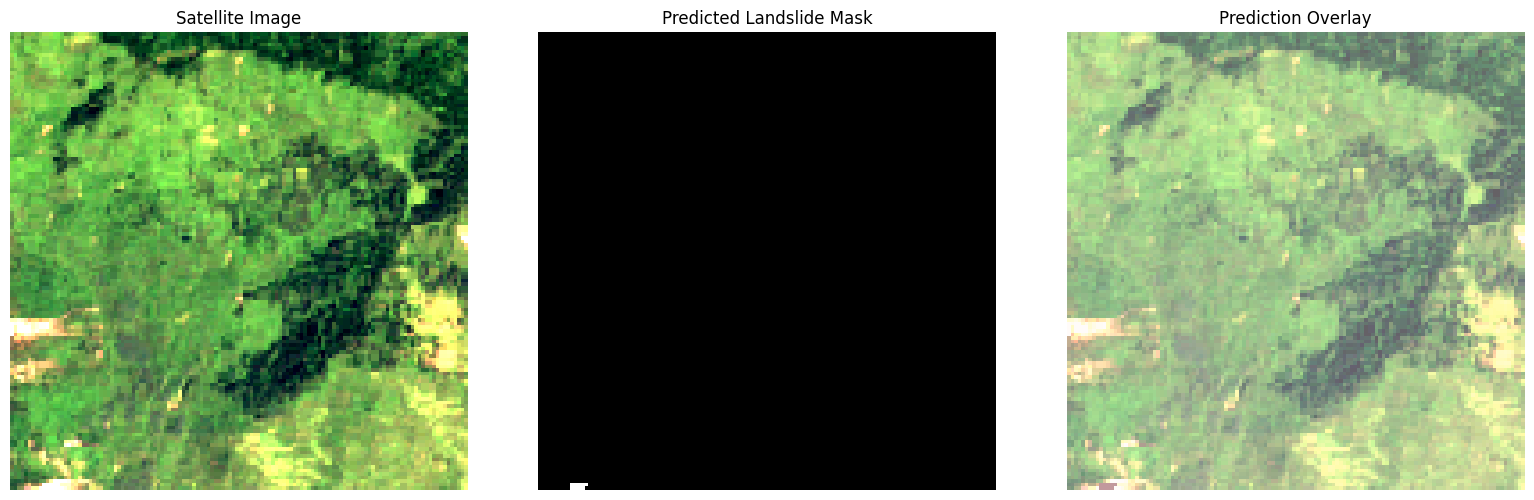

In [27]:
# Predict landslide regions in a new HDF5 satellite image

NEW_IMAGE_PATH = test_images[0]

with h5py.File(NEW_IMAGE_PATH, "r") as f:
    new_image = f["img"][:].astype(np.float32)

assert new_image.ndim == 3 and new_image.shape[-1] == 14, \
    f"Expected HWC image with 14 channels, got {new_image.shape}"

normalized_image = (new_image - channel_mean) / channel_std

input_tensor = torch.from_numpy(
    normalized_image
).permute(2, 0, 1).unsqueeze(0).float().to(device)

with torch.inference_mode():
    logits = model(input_tensor)
    probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

predicted_mask = (probability >= threshold).astype(np.uint8)

coverage = float(predicted_mask.mean() * 100)

print("NEW IMAGE PREDICTION")
print("-" * 40)
print("Image Shape:", new_image.shape)
print("Prediction:", "Landslide" if predicted_mask.any() else "No Landslide")
print("Landslide Pixels:", int(predicted_mask.sum()))
print("Landslide Coverage:", round(coverage, 4), "%")
print("Maximum Probability:", round(float(probability.max()), 6))
print("Mean Probability:", round(float(probability.mean()), 6))

# Display RGB composite, predicted mask, and overlay
rgb = new_image[:, :, [3, 2, 1]]
rgb = np.clip(
    (rgb - np.percentile(rgb, 2)) /
    (np.percentile(rgb, 98) - np.percentile(rgb, 2) + 1e-8),
    0, 1
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(rgb)
axes[0].set_title("Satellite Image")

axes[1].imshow(predicted_mask, cmap="gray")
axes[1].set_title("Predicted Landslide Mask")

axes[2].imshow(rgb)
axes[2].imshow(predicted_mask, cmap="Reds", alpha=0.4)
axes[2].set_title("Prediction Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 30. Understanding Segmentation Masks

The U-Net model performs pixel-level semantic segmentation rather than simply classifying an entire satellite image.

For each input image, the model generates a probability map representing the likelihood of each pixel belonging to a landslide region.

### Probability Map

The model produces raw logits, which are converted into probabilities using the sigmoid activation function.

Each pixel receives a probability between 0 and 1.

- Values closer to 1 indicate a higher predicted probability of landslide.
- Values closer to 0 indicate a higher predicted probability of background.

### Binary Segmentation Mask

A threshold of 0.5 is applied to convert the probability map into a binary mask.

- `1` – Predicted landslide pixel.
- `0` – Predicted background pixel.

### Prediction Overlay

The binary mask can be overlaid on the original satellite image to visualize the predicted landslide regions.

This helps users understand the spatial distribution of the regions identified by the model.

### Image-Level Classification

The model's segmentation output can also be converted into an image-level prediction:

- **Landslide:** At least one pixel is classified as landslide.
- **No Landslide:** No pixels are classified as landslide.

**Important:** A single predicted landslide pixel does not necessarily represent a confirmed landslide event. Predictions should be interpreted with appropriate domain knowledge and expert verification.

## 31. Project Limitations

Although the U-Net model provides a deep learning-based approach to landslide segmentation, several limitations should be considered.

### 1. Dataset Dependency
The model is trained on a specific satellite imagery dataset. Its performance may vary when applied to images from different geographical regions or datasets.

### 2. Spectral Channel Requirements
The model expects 14 input channels. Images with different channel configurations cannot be directly processed without appropriate preprocessing.

### 3. Prediction Uncertainty
Model predictions are probabilistic and may include false positives and false negatives.

### 4. Threshold Sensitivity
The binary segmentation output depends on the selected probability threshold of 0.5. Different thresholds may produce different prediction masks.

### 5. Unlabeled Test Dataset
The test dataset does not contain ground-truth masks in this workflow. Therefore, quantitative test performance cannot be independently verified.

### 6. Real-World Validation
Predictions should be validated using expert knowledge, field observations, or reliable reference data before being used for operational disaster management.

This model is intended for research and educational purposes and should not be treated as an independent disaster-warning system.

## 32. Future Improvements

Several improvements can be explored to enhance the accuracy, robustness, and practical usability of the landslide detection system.

### Model Improvements
- Experiment with Attention U-Net and other advanced segmentation architectures.
- Explore pretrained encoder backbones.
- Investigate alternative loss functions such as Focal Loss and Tversky Loss.
- Perform systematic hyperparameter optimization.

### Data Improvements
- Increase training data diversity across geographical regions.
- Apply suitable data augmentation techniques.
- Investigate class imbalance handling strategies.
- Evaluate the model on independent datasets.

### Prediction Improvements
- Optimize the probability threshold using validation data.
- Apply suitable post-processing techniques to reduce isolated false-positive pixels.
- Generate confidence and uncertainty visualizations.

### Deployment Improvements
- Develop a web-based prediction interface.
- Build an API for satellite image inference.
- Integrate prediction outputs with GIS software.
- Explore large-scale satellite image processing.

These improvements can help move the project toward a more robust and practical landslide segmentation system.

## 33. Conclusion

This project presents a deep learning-based approach for detecting landslide-affected regions in multispectral satellite imagery using a custom U-Net architecture.

The model processes 14-channel satellite images and performs binary semantic segmentation to identify potential landslide regions at the pixel level.

The complete workflow includes dataset exploration, preprocessing, normalization, model development, training, validation, performance evaluation, and test dataset inference.

The project also generates reusable model checkpoints and a CSV file containing image-level prediction summaries.

By combining satellite remote sensing data with deep learning, this project demonstrates the potential of automated image segmentation for landslide-related research and geospatial analysis.

Further improvements and independent real-world validation are necessary before considering operational applications.

## 34. Project Information & Acknowledgements

### Project Title
**Landslide Detection Using Deep Learning**

### Domain
Deep Learning, Computer Vision, Remote Sensing, and Disaster Management.

### Technologies
- Python
- PyTorch
- NumPy
- Pandas
- h5py
- Matplotlib
- Scikit-learn
- Kaggle

### Dataset Acknowledgement
This project uses the Landslide4Sense dataset for landslide segmentation research.

### Model
Custom U-Net architecture for binary semantic segmentation.

### Project Repository
The source code and project resources can be made available through the associated project repository.

### Disclaimer
This project is developed for educational and research purposes. Its predictions are not a substitute for professional geological assessment, field investigation, or official disaster-management decisions.

**Thank you for exploring this project!**